# 03 · Le filtre passe-bande

**But :** construire un filtre qui **garde une plage de fréquences** (les médiums, de 250 Hz à 4 kHz), puis assembler l'**égaliseur trois bandes** complet.

1. L'idée
2. Préparation
3. Le signal de test
4. Méthode n° 1 : différence de deux passe-bas
5. Méthode n° 2 : passe-bas puis passe-haut
6. Comparer avant / après
7. Monter le volume des médiums
8. L'égaliseur trois bandes
9. À retenir

Les notions de base sont expliquées au début du notebook 01, le passe-haut dans le notebook 02.

## 1. L'idée

Un **passe-bande** garde les fréquences **entre** deux coupures $f_1$ et $f_2$, et atténue tout le reste. Image : régler une radio sur une station, en éliminant les voisines.

On le construit avec les filtres déjà connus, de deux façons :

1. **Différence :** (tout ce qui est sous 4 kHz) − (tout ce qui est sous 250 Hz) = ce qui est entre les deux.
2. **Enchaînement :** un passe-bas à 4 kHz retire les aigus, puis un passe-haut à 250 Hz retire les graves.

## 2. Préparation

**Cellule suivante :** charge les outils, fixe les deux coupures et définit le passe-bas et le passe-haut des notebooks 01 et 02.

In [1]:
%matplotlib inline
import numpy as np
from outils import *          # mesures, graphiques et écoute (voir outils.py, inutile de le lire)

F1 = 250.0      # coupure basse (Hz) : frontière graves / médiums
F2 = 4000.0     # coupure haute (Hz) : frontière médiums / aigus
DUREE = 2.0     # durée du signal de test (s)

def lissage_exponentiel(x, alpha):
    # Passe-bas du notebook 01 : y[n] = y[n−1] + alpha × (x[n] − y[n−1])
    y = np.zeros(len(x))
    precedent = 0.0
    for n in range(len(x)):
        precedent = precedent + alpha * (x[n] - precedent)
        y[n] = precedent
    return y


def passe_bas(x, fc):
    alpha = 1 - np.exp(-2 * np.pi * fc / FS)       # réglage du notebook 01
    return lissage_exponentiel(x, alpha)


def passe_haut(x, fc):
    return x - passe_bas(x, fc)                    # notebook 02 : signal − passe-bas

## 3. Le signal de test

Les trois mêmes notes. Le passe-bande doit garder la médium (1 kHz).

**Cellule suivante :** crée le signal de test, l'affiche et propose de l'écouter.

88200 échantillons


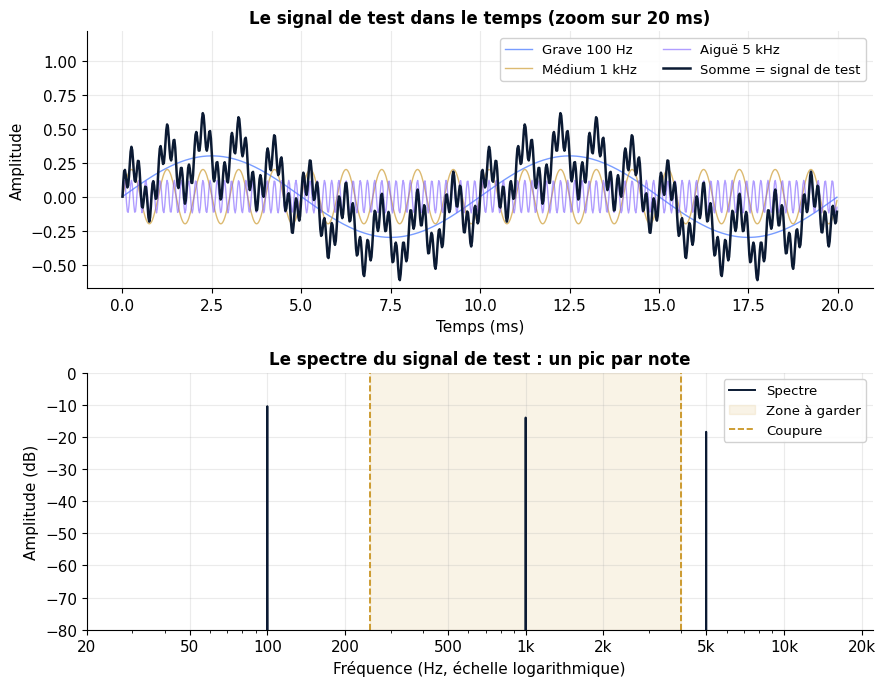

Signal de test — crête : 0.61


In [2]:
t = np.arange(int(DUREE * FS)) / FS        # les instants de mesure : 0, 1/FS, 2/FS, …

NOTES = {                                  # nom : (fréquence en Hz, amplitude)
    "Grave 100 Hz": (100, 0.30),
    "Médium 1 kHz": (1000, 0.20),
    "Aiguë 5 kHz": (5000, 0.12),
}
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in NOTES.items()}   # A·sin(2πft)
x = sum(sinusoides.values())               # le signal de test = la somme des trois notes

print(len(x), "échantillons")

tracer_signal(t, sinusoides, x, coupures=[F1, F2], zone=(F1, F2))
ecouter(x, "Signal de test")

## 4. Méthode n° 1 : différence de deux passe-bas

$$\text{médiums} = \text{passe-bas}_{4\,\text{kHz}}(x) - \text{passe-bas}_{250\,\text{Hz}}(x)$$

**Cellule suivante :** programme le passe-bande par différence, puis filtre le signal de test.

In [3]:
def passe_bande_difference(x, f1, f2):
    sous_f2 = passe_bas(x, f2)      # graves + médiums
    sous_f1 = passe_bas(x, f1)      # graves seules
    return sous_f2 - sous_f1        # il reste les médiums


y_diff = passe_bande_difference(x, F1, F2)

## 5. Méthode n° 2 : passe-bas puis passe-haut

$$\text{médiums} = \text{passe-haut}_{250\,\text{Hz}}\big(\text{passe-bas}_{4\,\text{kHz}}(x)\big)$$

Quand on enchaîne deux filtres, **leurs effets se multiplient** : si l'un laisse passer 50 % et l'autre 50 %, il passe 25 % au total.

**Cellule suivante :** programme le passe-bande par enchaînement, filtre le signal, et vérifie que l'ordre des deux filtres ne change rien.

In [4]:
def passe_bande_enchaine(x, f1, f2):
    sans_aigus = passe_bas(x, f2)       # 1er filtre : on retire les aigus
    return passe_haut(sans_aigus, f1)   # 2e filtre : on retire les graves


y_ench = passe_bande_enchaine(x, F1, F2)
print("Même résultat dans l'autre ordre :", np.allclose(y_ench, passe_bas(passe_haut(x, F1), F2)))

Même résultat dans l'autre ordre : True


## 6. Comparer avant / après

### Dans le temps

**Cellule suivante :** superpose le signal d'origine, la médium seule (l'objectif) et les deux sorties, sur 5 ms.

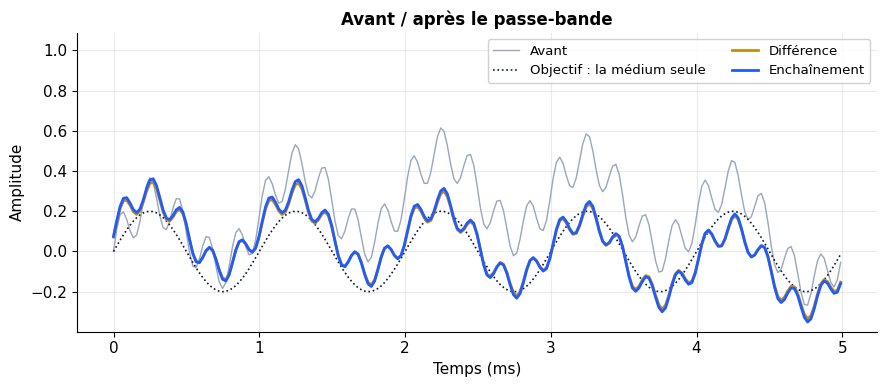

In [5]:
tracer_avant_apres(t, x, sinusoides["Médium 1 kHz"], "la médium seule",
                   [(y_diff, OR, "Différence"), (y_ench, BLEU, "Enchaînement")],
                   duree_ms=5, titre="Avant / après le passe-bande")

**À observer :**

les sorties suivent la médium, mais ondulent encore un peu : il reste une partie de la grave et de l'aiguë.

### Dans les fréquences

**Cellule suivante :** compare les spectres et donne la variation de chaque note en dB.

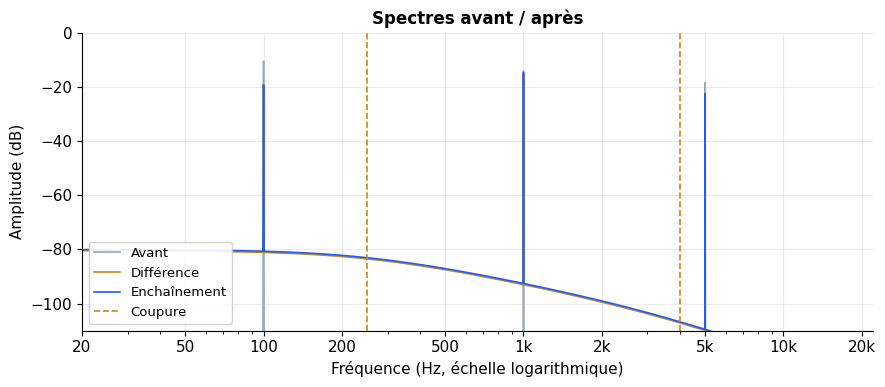

,Différence,Enchaînement
Note,,
Grave 100 Hz,-9.2 dB,-8.8 dB
Médium 1 kHz,-1.1 dB,-0.7 dB
Aiguë 5 kHz,-4.5 dB,-4.1 dB


In [6]:
sorties = [(y_diff, OR, "Différence"), (y_ench, BLEU, "Enchaînement")]
tracer_spectres(x, sorties, NOTES, coupures=[F1, F2])
tableau_notes(x, sorties, NOTES)

**À observer :**

- La médium passe presque entière (environ −1 dB).
- La grave et l'aiguë baissent, mais **beaucoup moins** qu'avec un passe-bas ou un passe-haut seul (environ −9 et −4 dB).
- Les deux méthodes donnent presque le même résultat.

### La réponse en fréquence

**Cellule suivante :** mesure la réponse des deux passe-bande, de 30 Hz à 20 kHz.

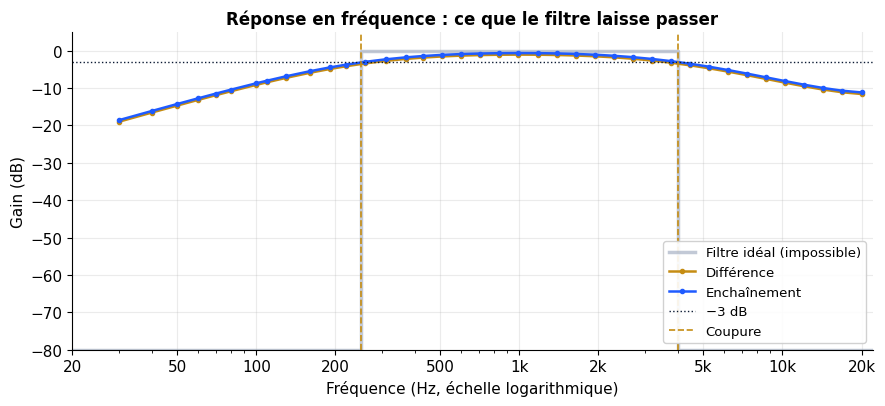

In [7]:
f_d, g_d = reponse_mesuree(lambda s: passe_bande_difference(s, F1, F2))
f_e, g_e = reponse_mesuree(lambda s: passe_bande_enchaine(s, F1, F2))
tracer_reponses([(f_d, g_d, OR, "Différence"), (f_e, g_e, BLEU, "Enchaînement")],
                coupures=[F1, F2], ideal=([20, F1, F1, F2, F2, FS / 2], [-80, -80, 0, 0, -80, -80]))

**À observer :**

- La courbe a une forme de **cloche** : maximale au milieu, elle descend des deux côtés.
- Les pentes sont douces : le passe-bande **déborde** largement sur les graves et les aigus.

### À l'écoute

**Cellule suivante :** affiche l'original et les deux versions filtrées.

In [8]:
ecouter(x, "Avant")
ecouter(y_diff, "Différence")
ecouter(y_ench, "Enchaînement")

Avant — crête : 0.61


Différence — crête : 0.35


Enchaînement — crête : 0.37


## 7. Monter le volume des médiums

Même recette : `mediums = passe_bande(x)`, `reste = x − mediums`, puis `x_eq = reste + facteur × mediums`.

**Cellule suivante :** monte les médiums de 6 dB, vérifie le retour exact à 0 dB et la crête, puis affiche graphiques, tableau et écoute.

À 0 dB, on retrouve x : True
Crête : 0.61 avant, 0.91 après


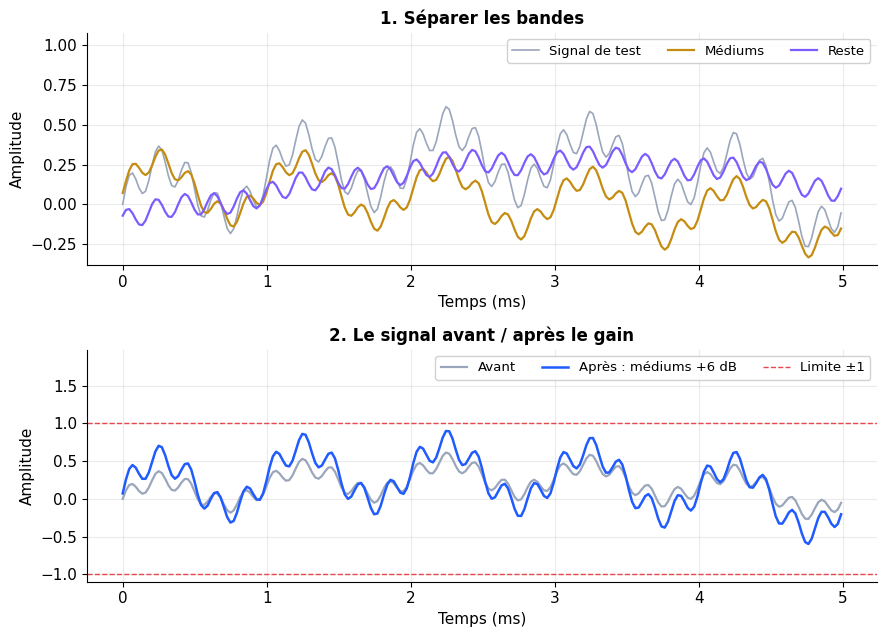

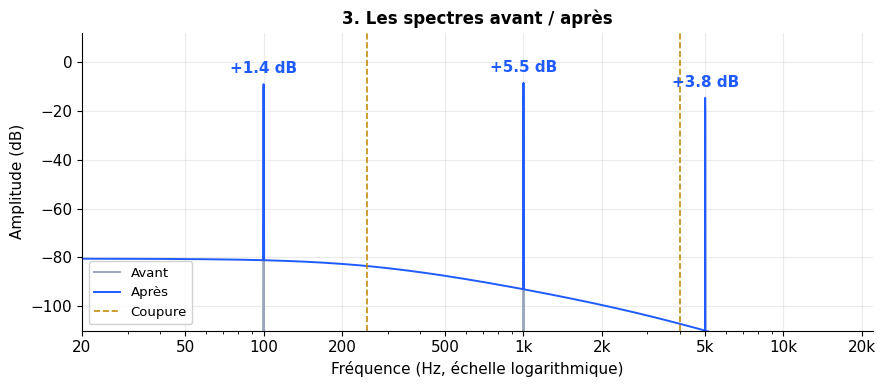

,Gain voulu,Gain obtenu
Note,,
Grave 100 Hz,+0.0 dB,+1.4 dB
Médium 1 kHz,+6.0 dB,+5.5 dB
Aiguë 5 kHz,+0.0 dB,+3.8 dB


Avant — crête : 0.61


Médiums +6 dB — crête : 0.91


In [9]:
G_DB = 6.0
facteur = 10 ** (G_DB / 20)

mediums = passe_bande_difference(x, F1, F2)   # 1. isoler les médiums
reste = x - mediums                           # 2. le reste
x_eq = reste + facteur * mediums              # 3. amplifier puis recombiner

print("À 0 dB, on retrouve x :", np.allclose(reste + mediums, x))
print(f"Crête : {np.max(np.abs(x)):.2f} avant, {np.max(np.abs(x_eq)):.2f} après")

tracer_egalisation(t, x, x_eq, [(mediums, OR, "Médiums"), (reste, VIOLET, "Reste")],
                   NOTES, coupures=[F1, F2], titre_apres=f"médiums {G_DB:+.0f} dB", duree_ms=5)
display(tableau_gains(x, x_eq, NOTES, {"Grave 100 Hz": 0, "Médium 1 kHz": G_DB, "Aiguë 5 kHz": 0}))
ecouter(x, "Avant")
ecouter(x_eq, f"Médiums {G_DB:+.0f} dB")

**À observer :**

la médium monte presque de 6 dB, mais la grave et surtout l'aiguë montent aussi : la bande des médiums déborde sur ses voisines, qui reçoivent une partie du gain.

## 8. L'égaliseur trois bandes

On assemble tout avec **deux passe-bas** seulement :

| Bande | Calcul |
|---|---|
| Graves | passe-bas à 250 Hz |
| Médiums | passe-bas à 4 kHz − passe-bas à 250 Hz |
| Aigus | signal − passe-bas à 4 kHz |

En additionnant les trois lignes, tout s'annule sauf le signal : **graves + médiums + aigus = x**. Avec des gains de 0 dB, l'égaliseur ne change donc rien. C'est exactement le calcul d'EGALIZE.

**Cellule suivante :** découpe le signal en trois bandes, vérifie que leur somme redonne `x`, applique un gain différent à chaque bande, puis affiche le résultat.

graves + médiums + aigus = x : True
Crête : 0.61 avant, 0.68 après


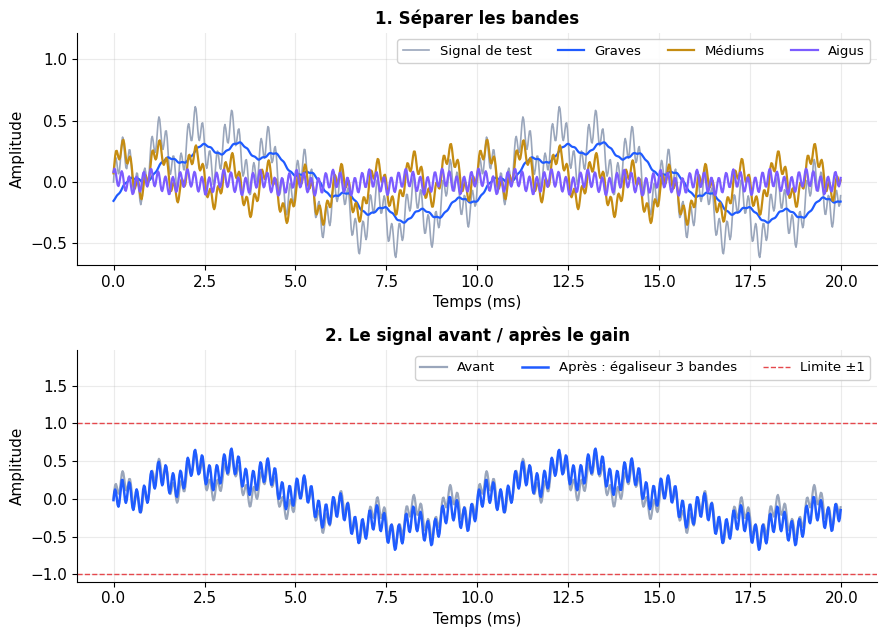

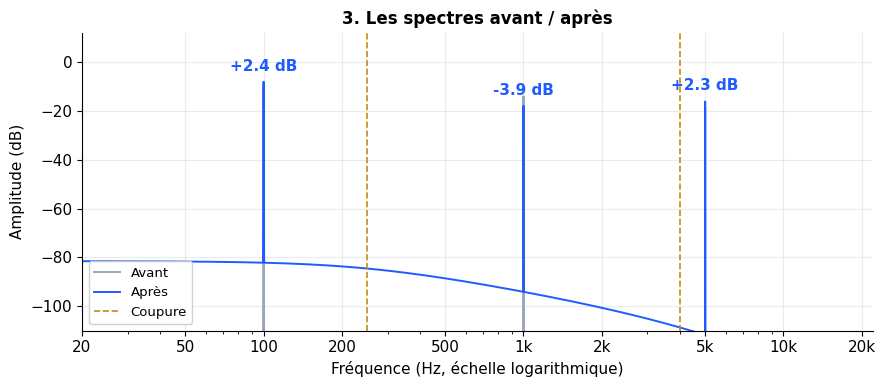

,Gain voulu,Gain obtenu
Note,,
Grave 100 Hz,+3.0 dB,+2.4 dB
Médium 1 kHz,-6.0 dB,-3.9 dB
Aiguë 5 kHz,+6.0 dB,+2.3 dB


Avant — crête : 0.61


Après l'égaliseur — crête : 0.68


In [10]:
GAINS_DB = {"graves": 3.0, "mediums": -6.0, "aigus": 6.0}     # essayez d'autres réglages

pb_f1 = passe_bas(x, F1)
pb_f2 = passe_bas(x, F2)
bandes = {"graves": pb_f1, "mediums": pb_f2 - pb_f1, "aigus": x - pb_f2}
print("graves + médiums + aigus = x :", np.allclose(sum(bandes.values()), x))

# chaque bande multipliée par son facteur, puis on additionne
x_eq = sum(10 ** (GAINS_DB[nom] / 20) * bande for nom, bande in bandes.items())
print(f"Crête : {np.max(np.abs(x)):.2f} avant, {np.max(np.abs(x_eq)):.2f} après")

tracer_egalisation(t, x, x_eq, [(bandes["graves"], BLEU, "Graves"), (bandes["mediums"], OR, "Médiums"),
                                (bandes["aigus"], VIOLET, "Aigus")],
                   NOTES, coupures=[F1, F2], titre_apres="égaliseur 3 bandes")
display(tableau_gains(x, x_eq, NOTES, {"Grave 100 Hz": GAINS_DB["graves"], "Médium 1 kHz": GAINS_DB["mediums"],
                                       "Aiguë 5 kHz": GAINS_DB["aigus"]}))
ecouter(x, "Avant")
ecouter(x_eq, "Après l'égaliseur")

**À observer :**

- Chaque note bouge **dans le bon sens**, mais pas exactement de la valeur demandée.
- Les bandes se chevauchent, donc chaque note reçoit un mélange du gain de sa bande et de celui de ses voisines.
- La solution : des filtres qui coupent plus net (par exemple Butterworth), pour que les bandes se chevauchent moins.

## 9. À retenir

- Un **passe-bande** garde une plage de fréquences entre $f_1$ et $f_2$.
- On l'obtient par **différence de deux passe-bas**, ou en **enchaînant** un passe-bas et un passe-haut.
- Quand on enchaîne deux filtres, leurs effets **se multiplient**, et l'ordre ne compte pas.
- Avec la méthode par différence, **graves + médiums + aigus = x** : l'égaliseur est neutre à 0 dB.
- Avec des filtres qui coupent doucement, les bandes **se chevauchent** : le gain d'une bande déborde sur ses voisines.

**Essayez :** mettez tous les gains à 0 dB, puis tous à +12 dB. Que se passe-t-il pour la crête ?